# Práctica 4 · Meta aprendizaje

Aldo Santiago Márquez

¿Cuánto aportan los ensambles después de ajustar los modelos base? Se conservan las
cinco configuraciones finales de la Práctica 3 y sus cinco particiones por estudiante.
Se trabaja con los atributos disponibles al cierre del **primer semestre**. Después
se transfiere la familia ganadora a Bank Marketing y se compara con otras alternativas.

Este notebook usa rutas relativas, semillas fijas y un paquete local importable para
que el archivo de entrega también pueda cargarse fuera de Jupyter. Ejecutar desde
la raíz del repositorio o desde `Practicas/`, con las dependencias de
`requirements_practica_04.txt`. No requiere descargar datos si se conserva el repositorio.

Las búsquedas usan los mismos pliegues que la comparación final, como protocolo de
selección de esta práctica. **Sus resultados tienen optimismo de selección**: no son
una estimación independiente ni validación anidada. Las configuraciones base también
fueron elegidas previamente usando estos estudiantes. No se reutilizan los F1 de P3,
que correspondían a otro procedimiento. La desviación entre pliegues no es un
intervalo de confianza ni demuestra superioridad estadística.

In [1]:
from pathlib import Path
from importlib.metadata import version
from datetime import datetime, timezone
from time import perf_counter
import hashlib
import json
import os
import platform
import sys
import warnings

import joblib
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, TunedThresholdClassifierCV
from threadpoolctl import threadpool_limits

BASE = Path.cwd() / 'Practicas' if (Path.cwd() / 'Practicas').is_dir() else Path.cwd()
assert (BASE / 'metaaprendizaje').is_dir(), 'Abre el notebook desde ICD/ o Practicas/.'
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
from metaaprendizaje.datos import cargar_desercion, cargar_bank, descargar_bank
from metaaprendizaje.bases import bases_desercion, ensambles_desercion
from metaaprendizaje.modelos import espacios_ensambles, bases_bank, adaptar_ganador_bank
from metaaprendizaje.evaluacion import (evaluar, optimizar, tabla_resultados,
    matriz_ganador, guardar_json, slug, jsonable)
from metaaprendizaje.curvas import (referencias, curvas_sesgo_varianza,
                                    correlacion_errores)

SEED = 2026
N_JOBS = min(8, os.cpu_count() or 1)
N_CONFIG = 50  # No reducir: mínimo requerido por familia optimizada.
REUTILIZAR_CACHE = True  # Solo acepta caché con iguales datos, CV, código y versiones.
SALIDAS = BASE / 'resultados_practica_04'
CACHE = BASE / '.cache_practica_04'
DS, BS = SALIDAS / 'desercion', SALIDAS / 'bank'
for carpeta in [DS, BS, CACHE / 'desercion', CACHE / 'bank']:
    carpeta.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='Bins whose width are too small.*')
warnings.filterwarnings('ignore', message='X does not have valid feature names, but LGBMClassifier.*')
LIBRERIAS = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib',
             'joblib', 'threadpoolctl', 'lightgbm', 'catboost', 'nbformat',
             'nbclient', 'ipykernel', 'jupyterlab']
VERSIONES = {'python': platform.python_version(), **{p: version(p) for p in LIBRERIAS}}
display(pd.Series(VERSIONES, name='Versión de esta ejecución').to_frame())
print(f'{N_JOBS} ajustes paralelos; un hilo de cálculo por estimador.')
INICIO = perf_counter()

,Versión de esta ejecución
python,3.12.10
numpy,2.3.5
pandas,2.2.3
scipy,1.18.1
scikit-learn,1.9.1
matplotlib,3.10.8
joblib,1.6.0
threadpoolctl,3.7.0
lightgbm,4.7.0
catboost,1.2.10


8 ajustes paralelos; un hilo de cálculo por estimador.


## Parte 1 · Deserción estudiantil

Se verifica la huella SHA-256 de los CSV contra P3. Los cinco pliegues se reconstruyen
desde `pliegues.csv`, por `id`, conservando el orden original. `id`, `Target` y los seis
atributos del segundo semestre quedan fuera de X. Imputación, codificación,
discretización y escalado permanecen dentro de cada modelo.

Las funciones de `metaaprendizaje/bases.py` reconstruyen los estimadores a partir de
`mejores_parametros.json` sin ejecutar representaciones de texto ni repetir búsquedas.
En SVM y logística se conservan las tasas académicas y pesos de bloques de P3.

In [2]:
Xd, yd, cv_d, ids_d = cargar_desercion(BASE)
bases_d = bases_desercion(BASE)
modelos_d = {**bases_d, **referencias(), **ensambles_desercion(BASE)}
resultados_d, parametros_d = {}, {}
display(yd.value_counts().rename_axis('Clase').to_frame('Estudiantes'))
print('X:', Xd.shape, '| cinco pliegues originales, semilla de origen 42')
for nombre, modelo in bases_d.items():
    parametros_d[nombre] = jsonable(modelo.get_params(deep=False))
    resultados_d[nombre] = evaluar(nombre, modelo, Xd, yd, cv_d, 'enrolled', DS,
        CACHE / 'desercion', n_jobs=N_JOBS, reutilizar=REUTILIZAR_CACHE)

,Estudiantes
Clase,
graduate,1767
dropout,1137
enrolled,635


X: (3539, 30) | cinco pliegues originales, semilla de origen 42
Árbol: resultados comprobados de caché


Naive Bayes: resultados comprobados de caché


kNN: resultados comprobados de caché


SVM: resultados comprobados de caché


Regresión logística: resultados comprobados de caché


### Varianza y sesgo

Se evalúan aparte el árbol sin límite y el tocón. Bagging de un árbol usa una muestra
bootstrap, por lo que ese punto no equivale al árbol independiente entrenado con todo
el pliegue. Cada pliegue construye su propio bagging y aumenta los árboles mediante
`warm_start=True` en 1, 5, 10, 20, 50, 100, 200, 300 y 400.

AdaBoost se ajusta con un máximo de 400 tocones y se recorre `staged_predict()`.
Si termina antes, se registra el número efectivo y no se inventan rondas posteriores.
Las bandas muestran una desviación entre pliegues; las curvas de entrenamiento ayudan
a interpretar el ajuste, pero F1 no constituye una descomposición formal de sesgo y varianza.

Árbol sin límite: resultados comprobados de caché


Bagging 400: resultados comprobados de caché


Tocón: resultados comprobados de caché


AdaBoost 400: resultados comprobados de caché


Curvas: resultados comprobados de caché


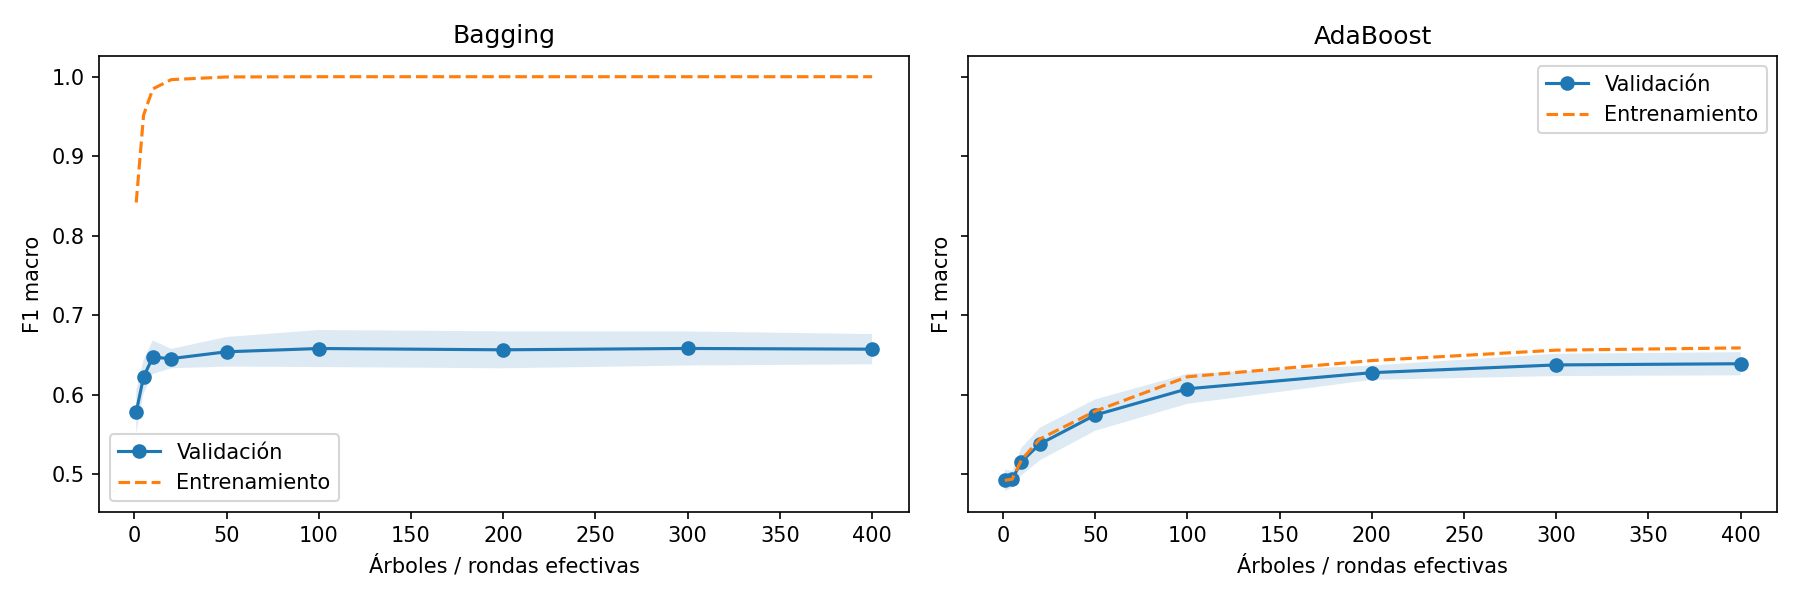

,modelo,f1_media,f1_desv,sensibilidad_media,entrenamiento_media_s
0,Árbol sin límite,0.594595,0.019074,0.377953,0.515259
1,Bagging 400,0.657107,0.019021,0.318110,32.488209
2,Tocón,0.491994,0.013509,0.000000,0.391065
3,AdaBoost 400,0.638790,0.014601,0.255118,27.843799


In [3]:
for nombre, modelo in referencias().items():
    resultados_d[nombre] = evaluar(nombre, modelo, Xd, yd, cv_d, 'enrolled', DS,
        CACHE / 'desercion', n_jobs=N_JOBS, reutilizar=REUTILIZAR_CACHE)
curvas = curvas_sesgo_varianza(Xd, yd, cv_d, DS, CACHE / 'desercion',
                              reutilizar=REUTILIZAR_CACHE)
# La última etapa warm_start debe coincidir con la evaluación independiente de 400.
bag_final = curvas[(curvas.familia == 'Bagging') & (curvas.cantidad == 400)].sort_values('pliegue')
np.testing.assert_allclose(bag_final.f1_macro,
                          resultados_d['Bagging 400']['pliegues'].f1_macro)
display(Image(filename=str(DS / 'curvas_sesgo_varianza.png')))
display(pd.DataFrame([resultados_d[n]['resumen'] for n in referencias()])[
    ['modelo', 'f1_media', 'f1_desv', 'sensibilidad_media', 'entrenamiento_media_s']])

### Combinar los cinco modelos

Se comparan votación dura, votación suave y stacking con meta-modelo logístico.
Para las dos combinaciones probabilísticas, `CalibratedClassifierCV` envuelve **la
Pipeline completa de SVM** y se ajusta solo dentro del entrenamiento de cada pliegue.
La calibración y el stacking usan tres particiones internas estratificadas. La
evaluación externa del stacking se hace con `cross_validate` y los cinco pliegues de P3.
Los pesos de clases se traducen al etiquetado interno de Voting/Stacking.

La correlación se calcula entre indicadores de error OOF (`predicción != real`),
alineados por estudiante, y no entre códigos numéricos de las clases.

Votación dura: resultados comprobados de caché


Votación suave: resultados comprobados de caché


Stacking logístico: resultados comprobados de caché

,Árbol,Naive Bayes,kNN,SVM,Regresión logística
Árbol,1.000,0.452,0.485,0.618,0.580
Naive Bayes,0.452,1.000,0.478,0.529,0.562
kNN,0.485,0.478,1.000,0.509,0.511
SVM,0.618,0.529,0.509,1.000,0.863
Regresión logística,0.580,0.562,0.511,0.863,1.000


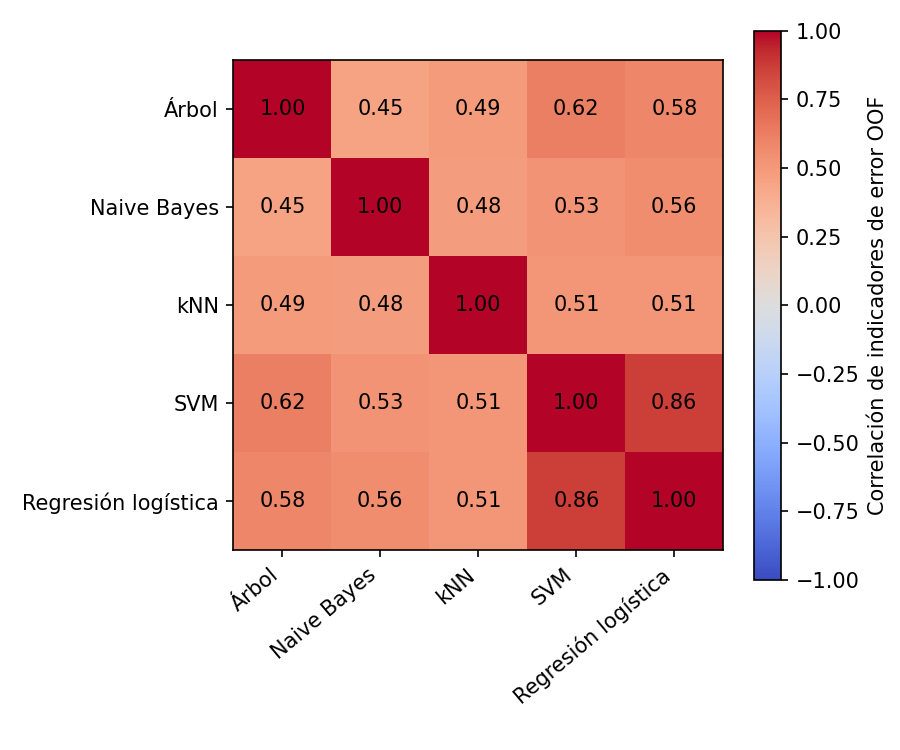

In [4]:
for nombre, modelo in ensambles_desercion(BASE).items():
    resultados_d[nombre] = evaluar(nombre, modelo, Xd, yd, cv_d, 'enrolled', DS,
        CACHE / 'desercion', n_jobs=N_JOBS, reutilizar=REUTILIZAR_CACHE)
corr_d = correlacion_errores(resultados_d, list(bases_d), yd, DS)
display(corr_d.round(3))
display(Image(filename=str(DS / 'correlacion_errores.png')))

### Bagging y boosting optimizados

Random Forest, Extra-Trees, LightGBM y CatBoost prueban **50 configuraciones diferentes
cada uno**, mediante `RandomizedSearchCV`. Se muestrea sin reemplazo de espacios finitos.
Los espacios completos se guardan en JSON y están definidos en `modelos.py`.

Los bosques comparan número de árboles, atributos por división, profundidad, tamaño
de hojas, criterio y pesos de clase; Extra-Trees también bootstrap. Los boostings
comparan tasa de aprendizaje, tamaño de árboles, regularización de hojas, submuestreo
de filas y columnas y balanceo. En LightGBM `subsample_freq=1` activa el submuestreo;
en CatBoost se usa bootstrap Bernoulli. Se compara también usar tasas académicas.
No se usa el pliegue externo como conjunto de early stopping.

La meseta es el mejor F1 acumulado en el **orden de muestreo**, no los candidatos
ordenados por resultado. Se informa la ganancia de las últimas 20 configuraciones;
≤0.001 indica una meseta local, sin garantizar un óptimo global.

Random Forest: búsqueda comprobada de caché


Evaluando Random Forest (5 pliegues)...


Random Forest: F1=0.6960 ± 0.0167


,Mejor configuración: Random Forest
modelo__n_estimators,200
modelo__min_samples_leaf,4
modelo__max_features,sqrt
modelo__max_depth,12
modelo__criterion,entropy
modelo__class_weight,balanced
features,{'clase': 'sklearn.preprocessing._function_tra...


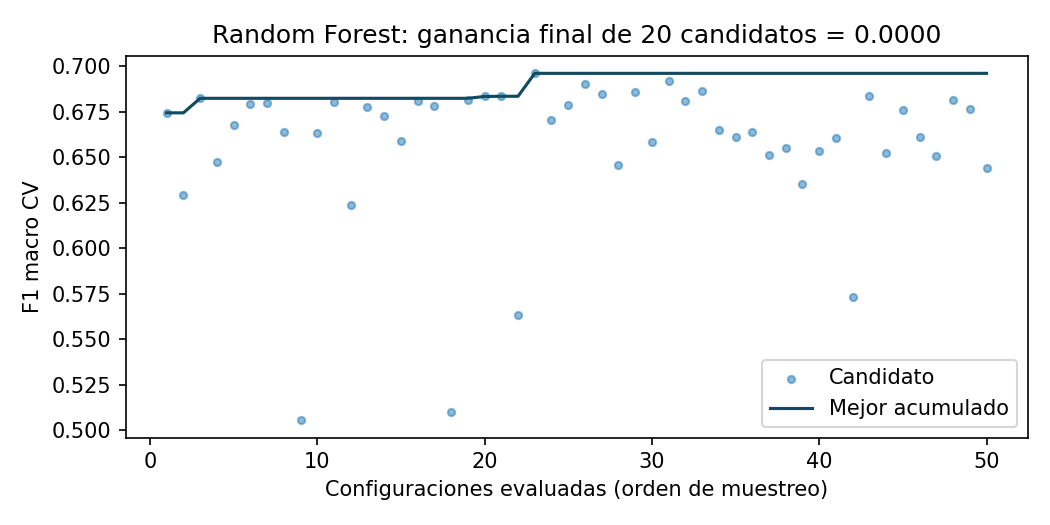

Extra-Trees: búsqueda comprobada de caché


Evaluando Extra-Trees (5 pliegues)...


Extra-Trees: F1=0.6907 ± 0.0110


,Mejor configuración: Extra-Trees
modelo__n_estimators,400
modelo__min_samples_leaf,4
modelo__max_features,sqrt
modelo__max_depth,20
modelo__criterion,entropy
modelo__class_weight,balanced_subsample
modelo__bootstrap,False
features,{'clase': 'sklearn.preprocessing._function_tra...


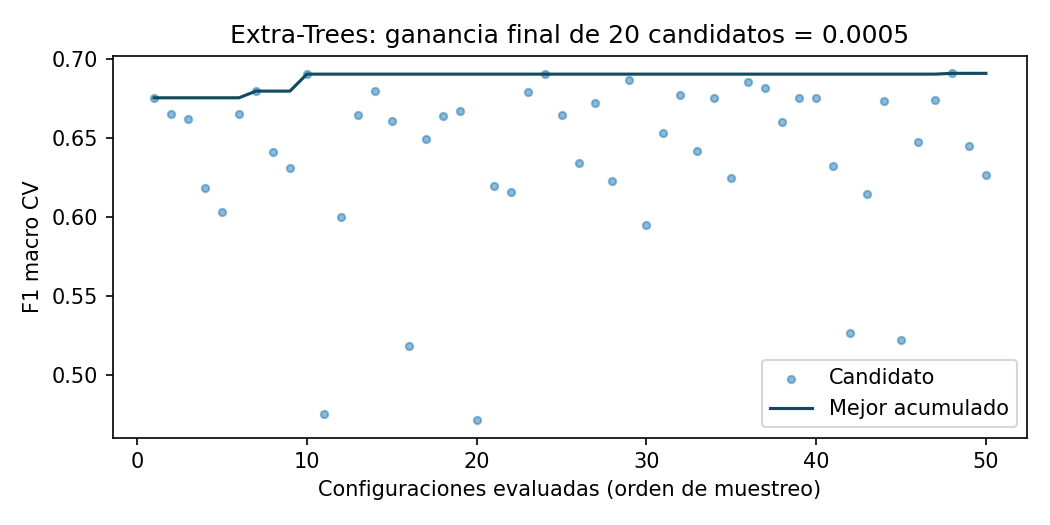

LightGBM: búsqueda comprobada de caché


Evaluando LightGBM (5 pliegues)...

LightGBM: F1=0.6968 ± 0.0139


,Mejor configuración: LightGBM
modelo__subsample,1.0
modelo__reg_lambda,0.5
modelo__num_leaves,63
modelo__n_estimators,100
modelo__min_child_samples,10
modelo__max_depth,8
modelo__learning_rate,0.04
modelo__colsample_bytree,0.6
modelo__class_weight,balanced
features,{'clase': 'sklearn.preprocessing._function_tra...


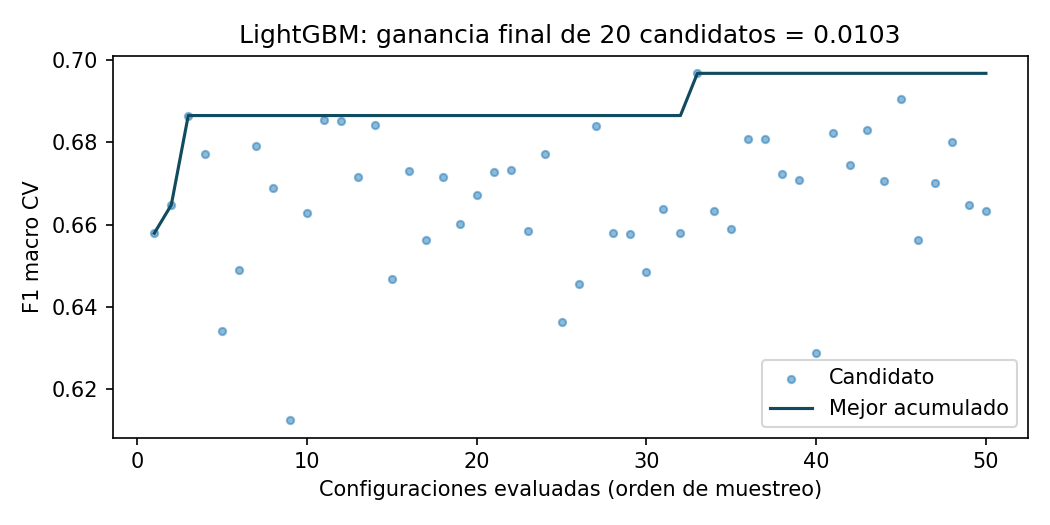

CatBoost: búsqueda comprobada de caché


Evaluando CatBoost (5 pliegues)...


CatBoost: F1=0.6916 ± 0.0133


,Mejor configuración: CatBoost
modelo__subsample,0.6
modelo__rsm,1.0
modelo__learning_rate,0.07
modelo__l2_leaf_reg,20.0
modelo__iterations,400
modelo__depth,6
modelo__auto_class_weights,Balanced
features,{'clase': 'sklearn.preprocessing._function_tra...


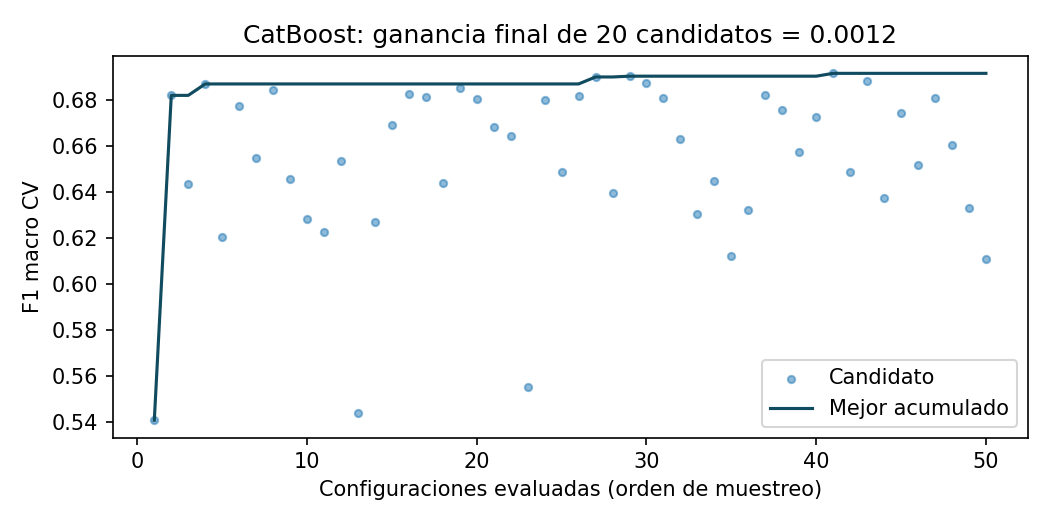

In [5]:
espacios_d = espacios_ensambles('desercion')
guardar_json(DS / 'espacios_busqueda.json', {n: p for n, (_, p) in espacios_d.items()})
for nombre, (modelo, espacio) in espacios_d.items():
    elegido, params, segundos = optimizar(nombre, modelo, espacio, Xd, yd, cv_d,
        DS, CACHE / 'desercion', N_CONFIG, N_JOBS, REUTILIZAR_CACHE)
    modelos_d[nombre], parametros_d[nombre] = elegido, params
    resultados_d[nombre] = evaluar(nombre, elegido, Xd, yd, cv_d, 'enrolled', DS,
        CACHE / 'desercion', N_JOBS, REUTILIZAR_CACHE, busqueda_s=segundos)
    display(pd.Series(jsonable(params), name=f'Mejor configuración: {nombre}').to_frame())
    display(Image(filename=str(DS / f'meseta_{slug(nombre)}.png')))

### Comparación completa

F1 se presenta como media ± desviación **muestral** (`ddof=1`) de los cinco pliegues.
La sensibilidad corresponde a `enrolled`. El tiempo de entrenamiento es la media
por pliegue de `fit_time`, separado del tiempo de búsqueda. Los CSV conservan también
el tiempo total de los cinco ajustes, los resultados por pliegue y los parámetros.
La matriz de confusión se muestra únicamente para el ganador y agrega predicciones OOF.

,modelo,F1 macro (media ± desv),sensibilidad_media,entrenamiento_media_s,busqueda_s
0,LightGBM,0.6968 ± 0.0139,0.563780,0.764764,38.309529
1,Random Forest,0.6960 ± 0.0167,0.554331,3.320461,226.388497
2,SVM,0.6918 ± 0.0059,0.560630,3.110598,0.000000
3,CatBoost,0.6916 ± 0.0133,0.588976,7.636223,134.820020
4,Regresión logística,0.6914 ± 0.0079,0.508661,1.152986,0.000000
5,Extra-Trees,0.6907 ± 0.0110,0.549606,5.722443,229.084891
6,Votación dura,0.6876 ± 0.0099,0.483465,3.315890,0.000000
7,Stacking logístico,0.6717 ± 0.0165,0.346457,12.713986,0.000000
8,Votación suave,0.6690 ± 0.0156,0.366929,3.942855,0.000000
9,Bagging 400,0.6571 ± 0.0190,0.318110,32.488209,0.000000


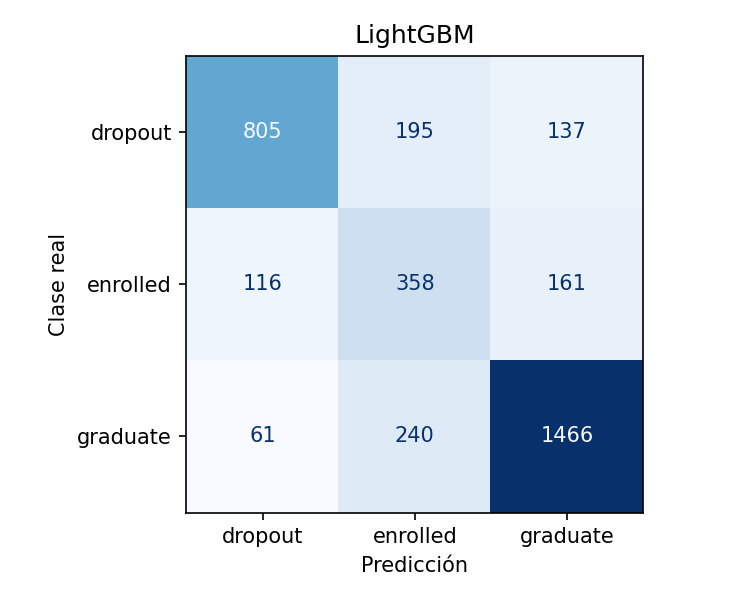

Ganador de deserción: LightGBM


,Configuración
modelo__subsample,1.0
modelo__reg_lambda,0.5
modelo__num_leaves,63
modelo__n_estimators,100
modelo__min_child_samples,10
modelo__max_depth,8
modelo__learning_rate,0.04
modelo__colsample_bytree,0.6
modelo__class_weight,balanced
features,{'clase': 'sklearn.preprocessing._function_tra...


In [6]:
tabla_d = tabla_resultados(resultados_d, DS, parametros_d)
columnas = ['modelo', 'F1 macro (media ± desv)', 'sensibilidad_media',
            'entrenamiento_media_s', 'busqueda_s']
display(tabla_d[columnas])
ganador_d, cm_d = matriz_ganador(tabla_d, resultados_d, yd,
                                 ['dropout', 'enrolled', 'graduate'], DS)
display(Image(filename=str(DS / 'matriz_confusion_mejor.png')))
print('Ganador de deserción:', ganador_d)
display(pd.Series(jsonable(parametros_d.get(ganador_d, {})), name='Configuración').to_frame())
oof_d = pd.DataFrame({'id': ids_d, 'real': yd})
for nombre, r in resultados_d.items():
    oof_d[nombre] = r['oof']
oof_d.to_csv(DS / 'predicciones_oof.csv', index=False)

## Parte 2 · Bank Marketing

Se usa exclusivamente `bank-additional-full.csv`, con 41,188 registros. X conserva
los valores y el orden originales, eliminando únicamente `duration` e `y`; y se codifica
`yes=1`, `no=0`. `duration` describe una llamada ya terminada, por lo que se excluye.
Las categorías `unknown` se conservan. Toda transformación aprendida se reajusta
dentro del modelo. Se exige `StratifiedKFold(5, shuffle=True, random_state=2026)` y
el F1 de cada alternativa procede literalmente de `cross_validate(..., scoring="f1_macro")`.

Se transfiere la **familia y configuración** ganadora de deserción, reconstruyendo
el preprocesamiento y entrenando desde cero con Bank. Un modelo ajustado con atributos
académicos no puede predecir directamente una suscripción bancaria.

Además de referencias simples con y sin pesos, se vuelven a optimizar las cuatro
familias de ensambles y la logística. En Bank también se compara one-hot frente a
codificación ordinal de categorías dentro de cada búsqueda. Se prueban votación suave,
stacking y un umbral que se optimiza **dentro de cada entrenamiento externo**, envolviendo
la Pipeline con `TunedThresholdClassifierCV(scoring="f1_macro")`. También se compara
CatBoost con categorías nativas, conservando los hiperparámetros seleccionados de su
búsqueda anterior para aislar el cambio de representación. CatBoost
[documenta ese tratamiento nativo](https://catboost.ai/docs/en/features/categorical-features).
Se ajusta el umbral de cada familia simple optimizada y de ambas representaciones
de CatBoost, además de la configuración transferida; las tres mejores familias
distintas también se combinan.

In [7]:
descargar_bank(BASE)  # No necesita internet si los originales ya están incluidos.
Xb, yb = cargar_bank(BASE)
cv_b = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
modelos_b, resultados_b, parametros_b = bases_bank(), {}, {}
nombre_transferido = f'Transferido: {ganador_d}'
modelos_b[nombre_transferido] = adaptar_ganador_bank(ganador_d, modelos_d[ganador_d])
display(yb.value_counts().rename(index={0: 'no', 1: 'yes'}).to_frame('Clientes'))
print('X original sin duration/y:', Xb.shape)
fold_b = np.zeros(len(yb), dtype=int)
for i, (_, va) in enumerate(cv_b.split(Xb, yb), 1):
    fold_b[va] = i
pd.DataFrame({'fila': np.arange(len(yb)), 'pliegue': fold_b}).to_csv(BS / 'pliegues.csv', index=False)
for nombre, modelo in modelos_b.items():
    parametros_b[nombre] = jsonable(modelo.get_params(deep=False))
    resultados_b[nombre] = evaluar(nombre, modelo, Xb, yb, cv_b, 1, BS,
        CACHE / 'bank', N_JOBS, REUTILIZAR_CACHE)

,Clientes
y,
no,36548
yes,4640


X original sin duration/y: (41188, 19)


Dummy: resultados comprobados de caché


Árbol: resultados comprobados de caché


Naive Bayes: resultados comprobados de caché


kNN: resultados comprobados de caché


Regresión logística: resultados comprobados de caché


Regresión logística balanceada: resultados comprobados de caché


Transferido: LightGBM: resultados comprobados de caché


Random Forest: búsqueda comprobada de caché


Evaluando Random Forest (5 pliegues)...


Random Forest: F1=0.7153 ± 0.0074


,Mejor configuración: Random Forest
pre__cat__codificar,{'clase': 'sklearn.preprocessing._encoders.Ord...
modelo__n_estimators,100
modelo__min_samples_leaf,4
modelo__max_features,sqrt
modelo__max_depth,None
modelo__criterion,gini
modelo__class_weight,balanced_subsample


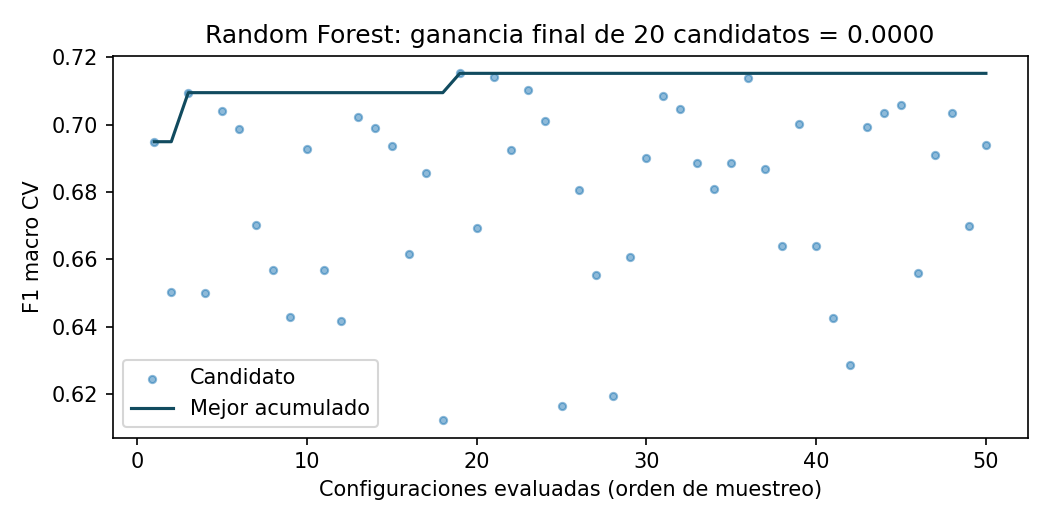

Extra-Trees: búsqueda comprobada de caché


Evaluando Extra-Trees (5 pliegues)...


Extra-Trees: F1=0.7068 ± 0.0047


,Mejor configuración: Extra-Trees
pre__cat__codificar,{'clase': 'sklearn.preprocessing._encoders.One...
modelo__n_estimators,200
modelo__min_samples_leaf,4
modelo__max_features,1.0
modelo__max_depth,12
modelo__criterion,entropy
modelo__class_weight,balanced_subsample
modelo__bootstrap,True


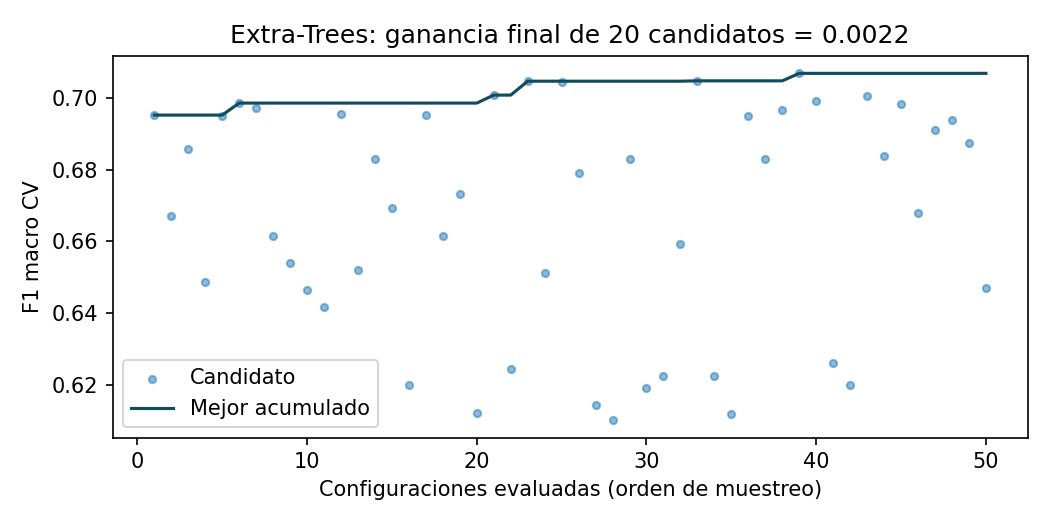

LightGBM: búsqueda comprobada de caché


LightGBM: resultados comprobados de caché


,Mejor configuración: LightGBM
pre__cat__codificar,{'clase': 'sklearn.preprocessing._encoders.Ord...
modelo__subsample,1.0
modelo__reg_lambda,5.0
modelo__num_leaves,31
modelo__n_estimators,100
modelo__min_child_samples,20
modelo__max_depth,6
modelo__learning_rate,0.02
modelo__colsample_bytree,0.6
modelo__class_weight,balanced


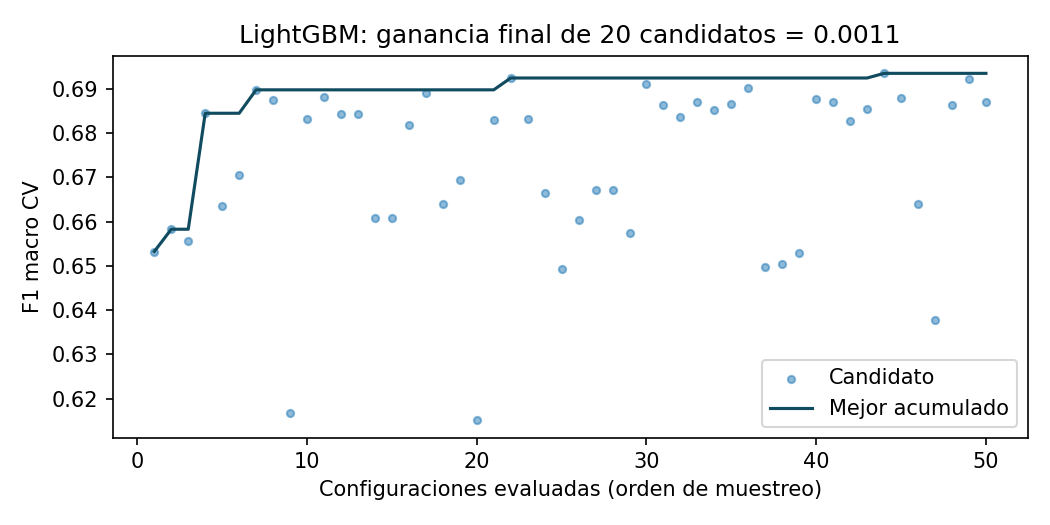

CatBoost: búsqueda comprobada de caché


Evaluando CatBoost (5 pliegues)...


CatBoost: F1=0.7173 ± 0.0082


,Mejor configuración: CatBoost
pre__cat__codificar,{'clase': 'sklearn.preprocessing._encoders.One...
modelo__subsample,0.8
modelo__rsm,1.0
modelo__learning_rate,0.1
modelo__l2_leaf_reg,1.0
modelo__iterations,400
modelo__depth,3
modelo__auto_class_weights,SqrtBalanced


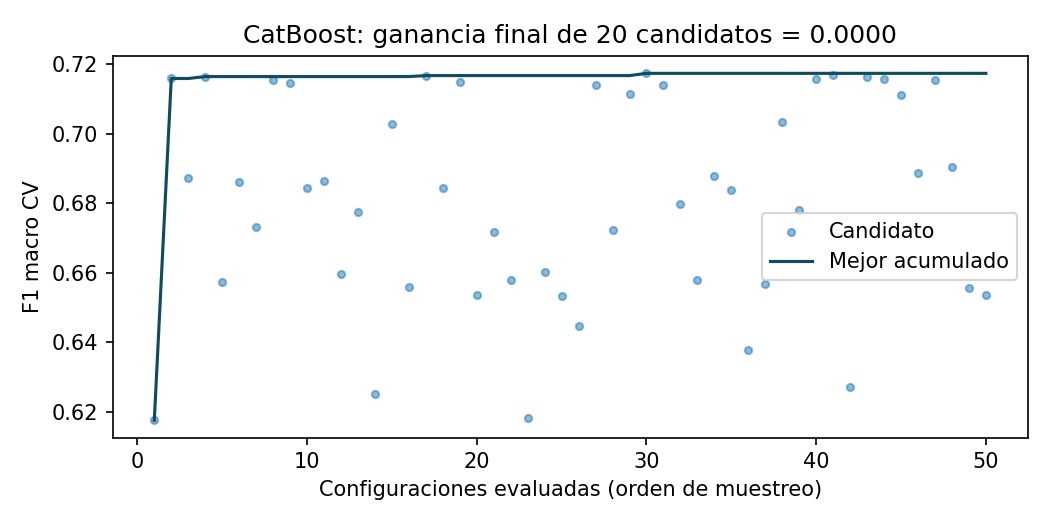

Logística optimizada: búsqueda comprobada de caché


Evaluando Logística optimizada (5 pliegues)...


Logística optimizada: F1=0.7063 ± 0.0063


,Mejor configuración: Logística optimizada
pre__cat__codificar__min_frequency,None
modelo__class_weight,"{'0': 1.0, '1': 4.0}"
modelo__C,100.0


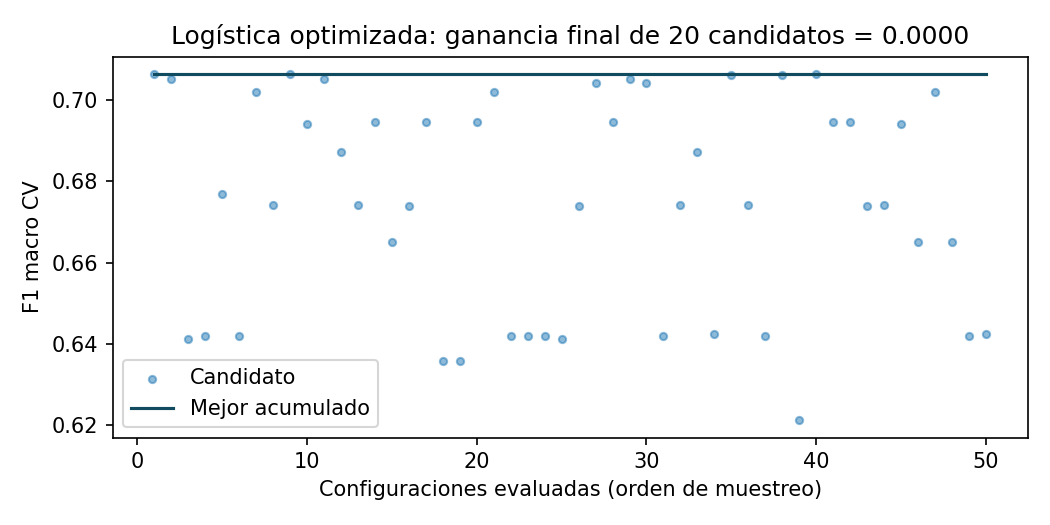

In [8]:
espacios_b = espacios_ensambles('bank')
lr = clone(modelos_b['Regresión logística'])
espacios_b['Logística optimizada'] = (lr, {
    'modelo__C': [0.001, 0.01, 0.1, 1., 10., 100.],
    'modelo__class_weight': [None, 'balanced', {0: 1., 1: 2.}, {0: 1., 1: 4.}],
    'pre__cat__codificar__min_frequency': [None, 0.001, 0.005],
})
guardar_json(BS / 'espacios_busqueda.json', {n: p for n, (_, p) in espacios_b.items()})
for nombre, (modelo, espacio) in espacios_b.items():
    elegido, params, segundos = optimizar(nombre, modelo, espacio, Xb, yb, cv_b,
        BS, CACHE / 'bank', N_CONFIG, N_JOBS, REUTILIZAR_CACHE)
    modelos_b[nombre], parametros_b[nombre] = elegido, params
    resultados_b[nombre] = evaluar(nombre, elegido, Xb, yb, cv_b, 1, BS,
        CACHE / 'bank', N_JOBS, REUTILIZAR_CACHE, busqueda_s=segundos)
    display(pd.Series(jsonable(params), name=f'Mejor configuración: {nombre}').to_frame())
    display(Image(filename=str(BS / f'meseta_{slug(nombre)}.png')))

In [9]:
# Contraste de representación: mismo CatBoost seleccionado, con categorías nativas.
categorias_bank = tuple(Xb.select_dtypes(exclude=np.number).columns)
pre_nativo = ColumnTransformer([
    ('cat', SimpleImputer(strategy='most_frequent', keep_empty_features=True),
        make_column_selector(dtype_exclude=np.number)),
    ('num', SimpleImputer(strategy='median', keep_empty_features=True),
        make_column_selector(dtype_include=np.number)),
], verbose_feature_names_out=False).set_output(transform='pandas')
nombre_nativo = 'CatBoost categórico'
modelos_b[nombre_nativo] = clone(modelos_b['CatBoost']).set_params(
    pre=pre_nativo, modelo__cat_features=categorias_bank)
parametros_b[nombre_nativo] = {**{k: v for k, v in parametros_b['CatBoost'].items()
                                if not k.startswith('pre__')},
    'pre': 'Categorías de texto e imputación dentro del Pipeline',
    'modelo__cat_features': categorias_bank}
resultados_b[nombre_nativo] = evaluar(nombre_nativo, modelos_b[nombre_nativo], Xb,
    yb, cv_b, 1, BS, CACHE / 'bank', N_JOBS, REUTILIZAR_CACHE)

# Elegir tres familias distintas; las dos representaciones CatBoost son una familia.
candidatos_b = list(espacios_b) + [nombre_nativo]
orden_b = sorted(candidatos_b, key=lambda n: resultados_b[n]['resumen']['f1_media'], reverse=True)
top_b, familias_elegidas = [], set()
for nombre in orden_b:
    familia = 'CatBoost' if nombre == nombre_nativo else nombre
    if familia not in familias_elegidas:
        top_b.append(nombre)
        familias_elegidas.add(familia)
    if len(top_b) == 3:
        break
componentes = [(f'm{i}', clone(modelos_b[n])) for i, n in enumerate(top_b)]
modelos_b['Votación suave'] = VotingClassifier(estimators=clone(componentes, safe=False),
                                              voting='soft', n_jobs=1)
modelos_b['Stacking logístico'] = StackingClassifier(
    estimators=clone(componentes, safe=False), stack_method='predict_proba',
    final_estimator=LogisticRegression(max_iter=4000, random_state=SEED),
    cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=1)
for nombre in ['Votación suave', 'Stacking logístico']:
    parametros_b[nombre] = {'familias': top_b}
    resultados_b[nombre] = evaluar(nombre, modelos_b[nombre], Xb, yb, cv_b, 1,
        BS, CACHE / 'bank', N_JOBS, REUTILIZAR_CACHE)
# El umbral se aprende solo con entrenamiento, en cada uno de los cinco pliegues.
for base_umbral in candidatos_b + [nombre_transferido]:
    nombre_umbral = f'Umbral interno: {base_umbral}'
    modelos_b[nombre_umbral] = TunedThresholdClassifierCV(
        estimator=clone(modelos_b[base_umbral]), scoring='f1_macro',
        cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
        thresholds=101, n_jobs=1, random_state=SEED)
    parametros_b[nombre_umbral] = {'familia': base_umbral, 'umbral': 'CV interna 3 pliegues',
                                  'parametros_base': parametros_b[base_umbral]}
    resultados_b[nombre_umbral] = evaluar(nombre_umbral, modelos_b[nombre_umbral],
        Xb, yb, cv_b, 1, BS, CACHE / 'bank', N_JOBS, REUTILIZAR_CACHE)

Evaluando CatBoost categórico (5 pliegues)...


CatBoost categórico: F1=0.7163 ± 0.0064


Votación suave: resultados comprobados de caché


Stacking logístico: resultados comprobados de caché


Evaluando Umbral interno: Random Forest (5 pliegues)...


Umbral interno: Random Forest: F1=0.7172 ± 0.0071


... (7 outputs left out)

Evaluando Umbral interno: CatBoost categórico (5 pliegues)...


Umbral interno: CatBoost categórico: F1=0.7156 ± 0.0057


Evaluando Umbral interno: Transferido: LightGBM (5 pliegues)...


Umbral interno: Transferido: LightGBM: F1=0.7180 ± 0.0077


### Resultados y modelo de entrega

La sensibilidad corresponde a `yes=1`. Los tiempos incluyen todos los ajustes
internos de stacking o del umbral cuando forman parte del modelo, y separan las
búsquedas de configuraciones. La matriz contiene únicamente predicciones OOF del ganador.
Se reajusta el ganador con los 41,188 registros y se guarda el estimador completo;
el archivo `.joblib` incluye su preprocesamiento y, si corresponde, su umbral.

,modelo,F1 macro (media ± desv),sensibilidad_media,entrenamiento_media_s,busqueda_s
0,Umbral interno: Transferido: LightGBM,0.7180 ± 0.0077,0.553233,14.314044,0.000000
1,Votación suave,0.7177 ± 0.0061,0.563793,66.025544,0.000000
2,CatBoost,0.7173 ± 0.0082,0.525216,6.116680,296.782650
3,Umbral interno: Random Forest,0.7172 ± 0.0071,0.537500,35.514090,0.000000
4,Umbral interno: Extra-Trees,0.7170 ± 0.0070,0.540086,157.612914,0.000000
5,Umbral interno: CatBoost,0.7167 ± 0.0068,0.552802,35.357931,0.000000
6,CatBoost categórico,0.7163 ± 0.0064,0.531466,47.159399,0.000000
7,Umbral interno: LightGBM,0.7161 ± 0.0057,0.566379,13.605126,0.000000
8,Umbral interno: CatBoost categórico,0.7156 ± 0.0057,0.543534,162.702064,0.000000
9,Random Forest,0.7153 ± 0.0074,0.558836,5.536025,635.573691


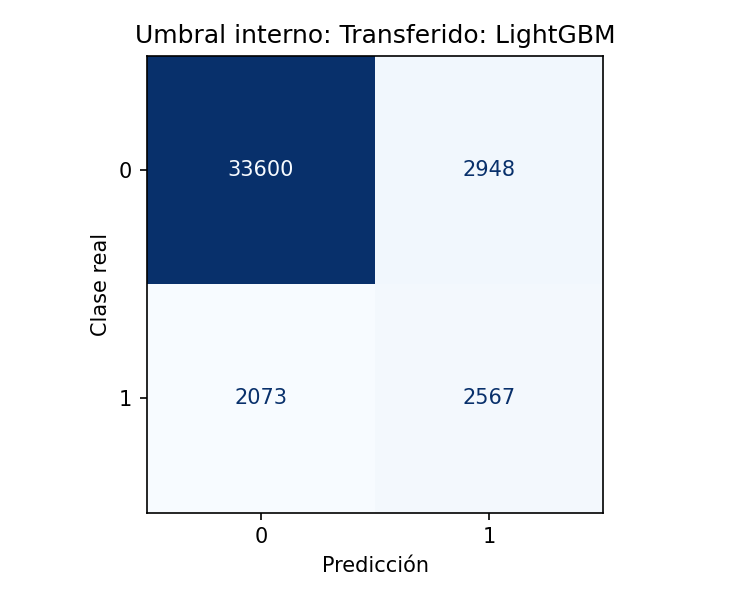

Ganador Bank: Umbral interno: Transferido: LightGBM


,Configuración
familia,Transferido: LightGBM
umbral,CV interna 3 pliegues
parametros_base,"{'memory': None, 'steps': [['features', 'passt..."


Modelo guardado y recargado: Aldo_Santiago_Marquez-umbral_interno_transferido_lightgbm.joblib; ajuste final 4.50s
Umbral del ajuste final: 0.6126179555297282


In [10]:
tabla_b = tabla_resultados(resultados_b, BS, parametros_b)
display(tabla_b[columnas])
ganador_b, cm_b = matriz_ganador(tabla_b, resultados_b, yb, [0, 1], BS)
display(Image(filename=str(BS / 'matriz_confusion_mejor.png')))
print('Ganador Bank:', ganador_b)
display(pd.Series(jsonable(parametros_b.get(ganador_b, {})), name='Configuración').to_frame())
modelo_final = clone(modelos_b[ganador_b])
inicio_fit = perf_counter()
with threadpool_limits(limits=1):
    modelo_final.fit(Xb, yb)
fit_final_s = perf_counter() - inicio_fit
archivo_modelo = BASE / f'Aldo_Santiago_Marquez-{slug(ganador_b)}.joblib'
joblib.dump(modelo_final, archivo_modelo, compress=3)
recargado = joblib.load(archivo_modelo)
with threadpool_limits(limits=1):
    np.testing.assert_array_equal(modelo_final.predict(Xb.iloc[:100]), recargado.predict(Xb.iloc[:100]))
print(f'Modelo guardado y recargado: {archivo_modelo.name}; ajuste final {fit_final_s:.2f}s')
if hasattr(modelo_final, 'best_threshold_'):
    print('Umbral del ajuste final:', modelo_final.best_threshold_)
oof_b = pd.DataFrame({'fila': np.arange(len(yb)), 'real': yb})
for nombre, r in resultados_b.items():
    oof_b[nombre] = r['oof']
oof_b.to_csv(BS / 'predicciones_oof.csv', index=False)

## Interpretación y conclusiones

Bagging promedia clasificadores inestables entrenados con remuestras: su contribución
esperada es reducir varianza, especialmente cuando sus errores no coinciden. No elimina
por sí solo un sesgo compartido. AdaBoost cambia el peso de los ejemplos y suma modelos
débiles; puede reducir el sesgo de un tocón al construir una frontera más compleja.
También puede verse afectado por ruido. Estos mecanismos no garantizan que F1 mejore
monótonamente al agregar árboles.

Random Forest y Extra-Trees añaden aleatoriedad para diversificar árboles. Los boostings
optimizados incorporan interacciones y regularización; su ventaja depende de estos datos
y del espacio buscado. Votación necesita errores complementarios; stacking aprende cómo
combinar probabilidades OOF y puede atenuar modelos menos útiles. Una alta correlación
de errores limita el beneficio esperado, aunque no determina por sí sola el ganador.

Las conclusiones cuantitativas siguientes se calculan de esta ejecución.

In [11]:
base_ganadora = max(bases_d, key=lambda n: resultados_d[n]['resumen']['f1_media'])
f_base = resultados_d[base_ganadora]['resumen']['f1_media']
f_d = tabla_d.iloc[0].f1_media
f_b = tabla_b.iloc[0].f1_media
pares = corr_d.where(np.triu(np.ones(corr_d.shape), k=1).astype(bool)).stack()
ganancia_bag = resultados_d['Bagging 400']['resumen']['f1_media'] - resultados_d['Árbol sin límite']['resumen']['f1_media']
ganancia_ada = resultados_d['AdaBoost 400']['resumen']['f1_media'] - resultados_d['Tocón']['resumen']['f1_media']
transfer = resultados_b[nombre_transferido]['resumen']['f1_media']
mejor_base_b = max(bases_bank(), key=lambda n: resultados_b[n]['resumen']['f1_media'])
f_base_b = resultados_b[mejor_base_b]['resumen']['f1_media']
familia_bank = (parametros_b[ganador_b]['familia'] if ganador_b.startswith('Umbral interno: ')
               else ganador_b.removeprefix('Transferido: '))
familia_canonica = lambda n: ('Regresión logística' if n.removeprefix('Transferido: ') in {
    'Logística optimizada', 'Regresión logística balanceada'} else
    'CatBoost' if n.removeprefix('Transferido: ') == 'CatBoost categórico'
    else n.removeprefix('Transferido: '))
coincidencia = ('La familia ganadora coincidió en ambos conjuntos.'
               if familia_canonica(familia_bank) == familia_canonica(ganador_d)
               else f'La familia/procedimiento ganador cambió de {ganador_d} a {familia_bank}.')
aportes = ' '.join(
    f'{familia}: en deserción obtuvo {resultados_d[familia]["resumen"]["f1_media"]:.4f} '
    f'({100*(resultados_d[familia]["resumen"]["f1_media"]-f_base):+.2f} puntos frente a {base_ganadora}); '
    f'en Bank {resultados_b[familia]["resumen"]["f1_media"]:.4f} '
    f'({100*(resultados_b[familia]["resumen"]["f1_media"]-f_base_b):+.2f} puntos frente a {mejor_base_b}).'
    for familia in ['Random Forest', 'Extra-Trees', 'LightGBM', 'CatBoost',
                    'Votación suave', 'Stacking logístico'])
sin_meseta = []
for etiqueta, carpeta in [('deserción', DS), ('Bank', BS)]:
    for ruta in sorted(carpeta.glob('mejor_*.json')):
        detalle = json.loads(ruta.read_text(encoding='utf-8'))
        if not detalle['meseta_local_001']:
            sin_meseta.append(f'{etiqueta}/{ruta.stem.removeprefix("mejor_")}')
texto_meseta = ('No se alcanzó el criterio de meseta local en ' + ', '.join(sin_meseta) +
    '; 50 configuraciones no bastan para afirmar estabilización en esas búsquedas.'
    if sin_meseta else 'Todas las búsquedas cumplieron el criterio local de meseta declarado.')
texto = (
    f'En deserción ganó **{ganador_d}**, con F1 macro {f_d:.4f}; la mejor base fija fue '
    f'{base_ganadora} ({f_base:.4f}). La diferencia fue {(f_d-f_base)*100:+.2f} puntos '
    f'porcentuales. Bagging 400 cambió el F1 del árbol sin límite en {ganancia_bag*100:+.2f} '
    f'puntos; AdaBoost cambió el del tocón en {ganancia_ada*100:+.2f} puntos.\n\n'
    f'Las correlaciones de error entre las cinco bases fueron de {pares.min():.3f} a '
    f'{pares.max():.3f}, con media {pares.mean():.3f}. Son errores OOF de estas muestras; '
    f'la complementariedad observada debe interpretarse junto a la calidad de cada base.\n\n'
    f'En Bank ganó **{ganador_b}**, con F1 macro {f_b:.4f} y sensibilidad yes '
    f'{tabla_b.iloc[0].sensibilidad_media:.4f}. Transferir la configuración de {ganador_d} '
    f'produjo {transfer:.4f}: la diferencia del mejor procedimiento Bank fue '
    f'{(f_b-transfer)*100:+.2f} puntos. '
    f'La tabla permite distinguir transferir la configuración, volver a optimizarla y '
    f'cambiar de familia; no se afirma que una familia sea universalmente superior.\n\n'
    f'{coincidencia} La configuración transferida se reajustó con datos bancarios; '
    f'una coincidencia de familia no implica que sirvan las mismas variables, pesos o umbral.\n\n'
    f'{aportes} En deserción las combinaciones usan los cinco base; en Bank usan las tres '
    f'familias optimizadas con mayor F1. Esta diferencia debe considerarse al compararlas.\n\n'
    f'En Bank, CatBoost con categorías nativas obtuvo '
    f'{resultados_b[nombre_nativo]["resumen"]["f1_media"]:.4f}, una diferencia de '
    f'{100*(resultados_b[nombre_nativo]["resumen"]["f1_media"]-resultados_b["CatBoost"]["resumen"]["f1_media"]):+.2f} '
    f'puntos frente a su representación codificada, manteniendo los hiperparámetros del clasificador.\n\n'
    f'{texto_meseta} La meseta es local al muestreo y no demuestra optimalidad global.\n\n'
    f'En deserción, enrolled representa {yd.eq("enrolled").mean():.2%} de las filas; '
    f'en Bank, yes representa {yb.mean():.2%}. El primero distingue tres situaciones '
    f'académicas y el segundo una respuesta binaria menos frecuente. Son diferencias '
    f'compatibles con cambios en pesos, sensibilidad y umbral; las tablas no demuestran '
    f'causalmente por qué ganó un modelo. Bank también incluye indicadores económicos '
    f'y contactos previos, mientras deserción contiene rendimiento académico.\n\n'
    f'Las búsquedas comparten los pliegues de la tabla: elegir entre configuraciones y '
    f'familias introduce optimismo. Las desviaciones no prueban significación. Bank viene '
    f'ordenado por fecha, pero la consigna exige particiones aleatorias estratificadas; '
    f'este resultado no demuestra rendimiento en campañas futuras. No se conocen las '
    f'etiquetas de prueba de deserción ni se garantiza un lugar en la clasificación del curso.'
)
display(Markdown(texto))
(SALIDAS / 'conclusiones.md').write_text(texto + '\n', encoding='utf-8')
huellas = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in [
    BASE/'datos/desercion-entrenamiento.csv', BASE/'datos/desercion-prueba.csv',
    BASE/'datos/bank-additional-full.csv']}
metadata = {'ejecucion_utc': datetime.now(timezone.utc).isoformat(), 'versiones': VERSIONES,
    'semilla_desercion_original': 42, 'semilla_busqueda_y_bank': SEED,
    'n_configuraciones_por_familia': N_CONFIG, 'n_jobs': N_JOBS,
    'huellas_datos_sha256': huellas, 'ganador_desercion': ganador_d, 'ganador_bank': ganador_b,
    'modelo_entrega': archivo_modelo.name, 'modelo_sha256': hashlib.sha256(archivo_modelo.read_bytes()).hexdigest(),
    'f1_bank': float(f_b), 'f1_desercion': float(f_d), 'fit_final_s': fit_final_s,
    'umbral_final': getattr(modelo_final, 'best_threshold_', None),
    'desviacion': 'muestral ddof=1', 'cache_habilitada': REUTILIZAR_CACHE,
    'alcance': 'seleccion con los mismos pliegues; no validacion anidada',
    'segundos_esta_ejecucion_notebook': perf_counter()-INICIO}
guardar_json(SALIDAS/'metadatos.json', metadata)
# JSON estricto: algunos encoders declaran NaN como centinela de configuración.
# Se representa como texto en los reportes; los estimadores conservan su valor real.
for ruta_json in SALIDAS.rglob('*.json'):
    contenido = json.loads(ruta_json.read_text(encoding='utf-8'), parse_constant=str)
    ruta_json.write_text(json.dumps(contenido, ensure_ascii=False, indent=2,
                                    allow_nan=False), encoding='utf-8')
print('Resultados completos en', SALIDAS.relative_to(BASE))

En deserción ganó **LightGBM**, con F1 macro 0.6968; la mejor base fija fue SVM (0.6918). La diferencia fue +0.49 puntos porcentuales. Bagging 400 cambió el F1 del árbol sin límite en +6.25 puntos; AdaBoost cambió el del tocón en +14.68 puntos.

Las correlaciones de error entre las cinco bases fueron de 0.452 a 0.863, con media 0.559. Son errores OOF de estas muestras; la complementariedad observada debe interpretarse junto a la calidad de cada base.

En Bank ganó **Umbral interno: Transferido: LightGBM**, con F1 macro 0.7180 y sensibilidad yes 0.5532. Transferir la configuración de LightGBM produjo 0.6959: la diferencia del mejor procedimiento Bank fue +2.21 puntos. La tabla permite distinguir transferir la configuración, volver a optimizarla y cambiar de familia; no se afirma que una familia sea universalmente superior.

La familia ganadora coincidió en ambos conjuntos. La configuración transferida se reajustó con datos bancarios; una coincidencia de familia no implica que sirvan las mismas variables, pesos o umbral.

Random Forest: en deserción obtuvo 0.6960 (+0.42 puntos frente a SVM); en Bank 0.7153 (+4.13 puntos frente a Regresión logística balanceada). Extra-Trees: en deserción obtuvo 0.6907 (-0.12 puntos frente a SVM); en Bank 0.7068 (+3.29 puntos frente a Regresión logística balanceada). LightGBM: en deserción obtuvo 0.6968 (+0.49 puntos frente a SVM); en Bank 0.6935 (+1.95 puntos frente a Regresión logística balanceada). CatBoost: en deserción obtuvo 0.6916 (-0.02 puntos frente a SVM); en Bank 0.7173 (+4.33 puntos frente a Regresión logística balanceada). Votación suave: en deserción obtuvo 0.6690 (-2.28 puntos frente a SVM); en Bank 0.7177 (+4.37 puntos frente a Regresión logística balanceada). Stacking logístico: en deserción obtuvo 0.6717 (-2.01 puntos frente a SVM); en Bank 0.6751 (+0.12 puntos frente a Regresión logística balanceada). En deserción las combinaciones usan los cinco base; en Bank usan las tres familias optimizadas con mayor F1. Esta diferencia debe considerarse al compararlas.

En Bank, CatBoost con categorías nativas obtuvo 0.7163, una diferencia de -0.09 puntos frente a su representación codificada, manteniendo los hiperparámetros del clasificador.

No se alcanzó el criterio de meseta local en deserción/catboost, deserción/lightgbm, Bank/extra_trees, Bank/lightgbm; 50 configuraciones no bastan para afirmar estabilización en esas búsquedas. La meseta es local al muestreo y no demuestra optimalidad global.

En deserción, enrolled representa 17.94% de las filas; en Bank, yes representa 11.27%. El primero distingue tres situaciones académicas y el segundo una respuesta binaria menos frecuente. Son diferencias compatibles con cambios en pesos, sensibilidad y umbral; las tablas no demuestran causalmente por qué ganó un modelo. Bank también incluye indicadores económicos y contactos previos, mientras deserción contiene rendimiento académico.

Las búsquedas comparten los pliegues de la tabla: elegir entre configuraciones y familias introduce optimismo. Las desviaciones no prueban significación. Bank viene ordenado por fecha, pero la consigna exige particiones aleatorias estratificadas; este resultado no demuestra rendimiento en campañas futuras. No se conocen las etiquetas de prueba de deserción ni se garantiza un lugar en la clasificación del curso.

Resultados completos en resultados_practica_04


## Fuentes y entrega

[UCI · Deserción](https://archive.ics.uci.edu/dataset/697) y
[CSV del curso](https://github.com/husseinlopez/icd2026/tree/main/datos).
[UCI · Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing),
[DOI](https://doi.org/10.24432/C5K306), licencia CC BY 4.0. El archivo
`bank-additional-names.txt` incluido documenta la variante de 41,188 filas y sus variables.

Documentación oficial: [bagging y boosting](https://scikit-learn.org/stable/modules/ensemble.html),
[calibración](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibratedClassifierCV.html),
[stacking](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html),
[cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html),
[RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html),
[ajuste del umbral](https://scikit-learn.org/stable/modules/classification_threshold.html),
[LightGBM](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html) y
[CatBoost](https://catboost.ai/docs/en/references/training-parameters/common).

Entrega: enlace al [repositorio](https://github.com/Aldous6/ICD-2026), este notebook con
sus salidas y el `.joblib` anunciado arriba. El README explica instalación, rutas,
caché y cómo cargar el modelo; conservar el paquete `metaaprendizaje/` junto a él.
Para recalcular todo desde cero, usar `REUTILIZAR_CACHE=False` y Restart & Run All.